# DPG, DDPG and TD3 on Moving Reacher

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

The saved code correctly distinguishes termination from truncation for target bootstrapping. The short single-seed TD3 ablations do not consistently favor the full algorithm; retain the actual results rather than claiming all components improved performance. Run-All is blocked by the missing custom environment.


# Deterministic Actor-Critic: DPG, DDPG, and TD3

>- **NAME:**
>- **STUDENT ID:**

In this notebook, the goal is to build deterministic actor-critic methods from the ground up and connect each implementation detail to the theory from the homework. We will move from the deterministic policy-gradient identity to practical deep continuous-control algorithms, and then study why DDPG can fail and how TD3 fixes several of its failure modes.

We will implement and compare the following methods:

$$
\text{DPG}
\quad\longrightarrow\quad
\text{DDPG}
\quad\longrightarrow\quad
\text{TD3}.
$$

This cell standardizes the PyTorch installation used by the notebook. It is needed if you want to use P100 on Kaggle!

First, it removes any preinstalled versions of torch, torchvision, and torchaudio. Kaggle environments often come with these packages already installed, but their versions may differ from the versions expected by this homework. The uninstall command is allowed to fail without stopping the notebook, because some of the packages may not be installed yet.

Second, it installs fixed versions of the PyTorch stack:

- torch==2.7.1
- torchvision==0.22.1
- torchaudio==2.7.1

Using exact versions makes the notebook more reproducible across students and avoids version mismatches between PyTorch, torchvision, and torchaudio.

In [1]:
!python -m pip uninstall -y torch torchvision torchaudio || true

!python -m pip install --no-cache-dir --force-reinstall torch==2.7.1 torchvision==0.22.1 torchaudio==2.7.1 --index-url https://download.pytorch.org/whl/cu126

Found existing installation: torch 2.7.1+cu118
Uninstalling torch-2.7.1+cu118:
  Successfully uninstalled torch-2.7.1+cu118
Found existing installation: torchvision 0.22.1+cu118
Uninstalling torchvision-0.22.1+cu118:
  Successfully uninstalled torchvision-0.22.1+cu118
Found existing installation: torchaudio 2.7.1+cu118
Uninstalling torchaudio-2.7.1+cu118:
  Successfully uninstalled torchaudio-2.7.1+cu118
Looking in indexes: https://download.pytorch.org/whl/cu126
   ---------------------------------------- 0.0/2.7 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.7 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.7 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.7 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.7 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.7 GB 728.2 kB/s eta 1:02:11
   ---------------------------------------- 0.0/2.7 GB 799.2 kB/s eta 0:56:39
   -----------------------------


   ----------- ---------------------------- 0.8/2.7 GB 496.8 kB/s eta 1:04:34
   ----------- ---------------------------- 0.8/2.7 GB 496.3 kB/s eta 1:04:37
   ----------- ---------------------------- 0.8/2.7 GB 496.3 kB/s eta 1:04:37
   ----------- ---------------------------- 0.8/2.7 GB 496.3 kB/s eta 1:04:37
   ----------- ---------------------------- 0.8/2.7 GB 495.8 kB/s eta 1:04:41
   ----------- ---------------------------- 0.8/2.7 GB 495.8 kB/s eta 1:04:41
   ----------- ---------------------------- 0.8/2.7 GB 495.8 kB/s eta 1:04:41
   ----------- ---------------------------- 0.8/2.7 GB 497.4 kB/s eta 1:04:28
   ----------- ---------------------------- 0.8/2.7 GB 497.4 kB/s eta 1:04:28
   ----------- ---------------------------- 0.8/2.7 GB 498.4 kB/s eta 1:04:19
   ----------- ---------------------------- 0.8/2.7 GB 498.4 kB/s eta 1:04:19
   ----------- ---------------------------- 0.8/2.7 GB 498.6 kB/s eta 1:04:18
   ----------- ---------------------------- 0.8/2.7 GB 498.6 kB

This cell installs Gymnasium with MuJoCo support.

In [2]:
!pip install "gymnasium[mujoco]"

   ---------------------------------------- 0.0/6.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/6.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/6.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/6.0 MB ? eta -:--:--
   --- ------------------------------------ 0.5/6.0 MB 508.0 kB/s eta 0:00:11
   ----- ---------------------------------- 0.8/6.0 MB 568.6 kB/s eta 0:00:10
   ----- ---------------------------------- 0.8/6.0 MB 568.6 kB/s eta 0:00:10
   ------- -------------------------------- 1.0/6.0 MB 585.1 kB/s eta 0:00:09
   ------- -------------------------------- 1.0/6.0 MB 585.1 kB/s eta 0:00:09
   -------- ------------------------------- 1.3/6.0 MB 610.0 kB/s eta 0:00:08
   -------- ------------------------------- 1.3/6.0 MB 610.0 kB/s eta 0:00:08
   -------- ----------------------------

## Import Necessary Libraries

In [3]:
from pathlib import Path
from IPython.display import display
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from dataclasses import dataclass

try:
    from moving_target_reacher_env import make_moving_reacher, rollout_to_video, embed_video
except ModuleNotFoundError:
    # The uploaded helper file may be named this way in some environments.
    from HW3_moving_target_reacher_env import make_moving_reacher, rollout_to_video, embed_video


Note: Using a GPU is not strictly necessary for this assignment. The neural networks used here are small, and the majority of training time is spent running episodes in the environment (which occurs on the CPU), rather than performing backpropagation updates.

## Explore the Environment

The environment used in this project is a modified version of the Gymnasium MuJoCo `Reacher-v5` task. In the original Reacher environment, a two-link robotic arm must move its fingertip toward a target location. Here, the task is extended into a moving-target tracking problem, where the target position changes over time according to a predefined trajectory.

The environment is implemented as a wrapper around the base Reacher environment. At every timestep, the wrapper updates the target position using a target trajectory function and then recomputes the reward based on the current distance between the fingertip and the moving target. This changes the task from simply reaching a fixed point into continuously tracking a dynamic target.

Three target motion types are supported. A static target keeps the target fixed at a specified position. A circular target moves the target along a circular path using a radius, angular velocity, and center point. A Lissajous target produces a more complex periodic trajectory using separate amplitudes and angular velocities for the x and y directions. These different motion types allow the agent to be evaluated under both simple and more challenging tracking conditions.

The observation can include the original Reacher observation, the current target position, the current target velocity, time, and a phase representation based on sine and cosine features. Including the target position and velocity gives the agent direct information about where the target is and how it is moving, while the phase features provide a compact representation of periodic motion.

The action space is kept the same as the original Reacher environment. The agent outputs continuous torque commands for the arm joints, and these actions are applied to the MuJoCo simulation. The goal of the policy is to choose actions that keep the fingertip close to the moving target throughout the episode.

The reward consists of two components: a distance penalty and a control penalty. The distance penalty encourages the fingertip to stay close to the target, while the control penalty discourages unnecessarily large actions. Therefore, the agent must learn a balance between accurate tracking and smooth, efficient control.

At the start of each episode, the environment time and step counter are reset to zero, and the target is placed at its initial position. During each environment step, the target is synchronized with the current simulation time, the action is applied, the time is advanced, and the target is moved to its next position. Episodes terminate or truncate according to the underlying environment and the configured maximum episode length.

### Task Description

In this task, you will create and inspect a moving-target Reacher environment. The environment uses the MuJoCo `Reacher-v5` task with a circularly moving target. The target follows a circular trajectory with radius `0.15` and angular velocity `1.0`, and each episode is limited to `100` steps.

The observation includes the target position, target velocity, and phase information, allowing the agent to observe both where the target is and how it is moving. To verify that the environment works correctly, you will reset the environment, take random actions from the action space for a short rollout, and print useful diagnostic information such as the reward, fingertip-target distance, and target position at each step.

In [4]:
test_env = make_moving_reacher(
    motion="circle",
    env_id="Reacher-v5",
    radius=0.15,
    omega=1.0,
    max_episode_steps=100,
    include_target_pos=True,
    include_target_vel=True,
    include_phase=True,
    render_mode=None,
)

test_env.action_space.seed(0)
obs, info = test_env.reset(seed=0)
total_reward = 0.0

for step in range(10):
    action = test_env.action_space.sample()
    next_obs, reward, terminated, truncated, info = test_env.step(action)
    total_reward += float(reward)

    distance = info.get("distance", np.nan)
    target_x = info.get("target_x", np.nan)
    target_y = info.get("target_y", np.nan)
    print(
        f"step={step + 1:02d} | "
        f"reward={reward: .4f} | "
        f"distance={distance: .4f} | "
        f"target=({target_x: .4f}, {target_y: .4f})"
    )

    obs = next_obs
    if terminated or truncated:
        break

print(f"Total reward over test rollout: {total_reward:.4f}")
test_env.close()


step=01 | reward=-0.0628 | distance= 0.0600 | target=( 0.1500,  0.0030)
step=02 | reward=-0.0793 | distance= 0.0616 | target=( 0.1499,  0.0060)
step=03 | reward=-0.0773 | distance= 0.0665 | target=( 0.1497,  0.0090)
step=04 | reward=-0.0711 | distance= 0.0685 | target=( 0.1495,  0.0120)
step=05 | reward=-0.0752 | distance= 0.0676 | target=( 0.1493,  0.0150)
step=06 | reward=-0.0786 | distance= 0.0647 | target=( 0.1489,  0.0180)
step=07 | reward=-0.0747 | distance= 0.0609 | target=( 0.1485,  0.0209)
step=08 | reward=-0.0632 | distance= 0.0568 | target=( 0.1481,  0.0239)
step=09 | reward=-0.0598 | distance= 0.0545 | target=( 0.1476,  0.0269)
step=10 | reward=-0.0590 | distance= 0.0571 | target=( 0.1470,  0.0298)
Total reward over test rollout: -0.7009


### Task Description

In this task, you will generate a visualization of a rollout in the moving-target Reacher environment. The environment uses a circular target trajectory with radius `0.15`, angular velocity `1.0`, and an episode length of `150` steps. The observation includes the target position, target velocity, and phase features.

Instead of using the MuJoCo renderer, the rollout is recorded using a custom no-render video recorder. The recorder extracts the Reacher state directly from the environment and draws each frame with Matplotlib, including the robotic arm, moving target, fingertip position, target trail, fingertip trail, reward statistics, distance information, and action values.

A random policy is used by setting `policy=None`, so actions are sampled directly from the environment action space. The rollout is saved as a video file, summary statistics are printed, and the resulting video is embedded in the notebook for inspection.

In [5]:
video_dir = Path("videos")
video_dir.mkdir(parents=True, exist_ok=True)

random_env = make_moving_reacher(
    motion="circle",
    env_id="Reacher-v5",
    radius=0.15,
    omega=1.0,
    max_episode_steps=150,
    include_target_pos=True,
    include_target_vel=True,
    include_phase=True,
    render_mode=None,
)

video_path, video_stats = rollout_to_video(
    env=random_env,
    policy=None,
    video_path=video_dir / "random_policy_rollout.mp4",
    max_steps=150,
    fps=30,
    seed=0,
    trail_len=30,
)

random_env.close()
print(video_stats)
display(embed_video(video_path, width=720))


{'return': -28.420915912212806, 'num_steps': 150, 'num_frames': 151, 'mean_reward': -0.18947277274808538, 'mean_distance': 0.18261395307878653, 'final_distance': 0.20613518357276917}


## DPG

### Task Description

Implement a minimal Deterministic Policy Gradient agent for the moving-target Reacher environment. The agent should use:

- an actor network for deterministic continuous actions
- a critic network for estimating \(Q(s, a)\)
- Gaussian exploration noise
- optional target networks
- one-step TD critic updates
- actor updates through the critic

The actor outputs bounded actions using:

$$
a = b + s \tanh(f_\theta(o))
$$

where:

$$
s = \frac{a_{\text{high}} - a_{\text{low}}}{2},
\qquad
b = \frac{a_{\text{high}} + a_{\text{low}}}{2}
$$

The critic target is:

$$
y = r + \gamma (1 - d) Q(o', \mu(o'))
$$

or, when target networks are enabled:

$$
y = r + \gamma (1 - d) Q_{\text{targ}}(o', \mu_{\text{targ}}(o'))
$$

The critic minimizes:

$$
L_Q = \left(Q(o, a) - y\right)^2
$$

The actor maximizes the critic value, implemented as minimizing:

$$
L_\mu = -Q(o, \mu(o))
$$

For target networks, use soft updates:

$$
\theta_{\text{targ}} \leftarrow (1-\tau)\theta_{\text{targ}} + \tau\theta
$$

In [6]:
# -----------------------------
# Utilities
# -----------------------------

def mlp(sizes, activation=nn.ReLU, output_activation=nn.Identity):
    layers = []
    for i in range(len(sizes) - 1):
        act = activation if i < len(sizes) - 2 else output_activation
        layers += [nn.Linear(sizes[i], sizes[i + 1]), act()]
    return nn.Sequential(*layers)


@torch.no_grad()
def soft_update(net, target_net, tau):
    for param, target_param in zip(net.parameters(), target_net.parameters()):
        target_param.data.mul_(1.0 - tau)
        target_param.data.add_(tau * param.data)


@torch.no_grad()
def hard_update(net, target_net):
    target_net.load_state_dict(net.state_dict())


# -----------------------------
# Actor and critic
# -----------------------------

class DeterministicActor(nn.Module):
    def __init__(self, obs_dim, act_dim, act_low, act_high, hidden=(256, 256)):
        super().__init__()
        self.net = mlp([obs_dim, *hidden, act_dim])

        act_low = torch.as_tensor(act_low, dtype=torch.float32)
        act_high = torch.as_tensor(act_high, dtype=torch.float32)

        self.register_buffer("act_scale", (act_high - act_low) / 2)
        self.register_buffer("act_bias", (act_high + act_low) / 2)

    def forward(self, obs):
        return self.act_bias + self.act_scale * torch.tanh(self.net(obs))


class Critic(nn.Module):
    def __init__(self, obs_dim, act_dim, hidden=(256, 256)):
        super().__init__()
        self.q = mlp([obs_dim + act_dim, *hidden, 1])

    def forward(self, obs, act):
        x = torch.cat([obs, act], dim=-1)
        return self.q(x)


# -----------------------------
# Exploration noise
# -----------------------------

class GaussianNoise:
    def __init__(self, act_dim, std=0.1):
        self.act_dim = act_dim
        self.std = std

    def sample(self):
        return np.random.normal(0.0, self.std, size=self.act_dim).astype(np.float32)

    def reset(self):
        pass  # Gaussian noise is stateless.


# -----------------------------
# DPG config
# -----------------------------

@dataclass
class DPGConfig:
    gamma: float = 0.99
    actor_lr: float = 1e-3
    critic_lr: float = 1e-3
    tau: float = 0.005
    noise_std: float = 0.1
    hidden: tuple = (256, 256)
    use_target_networks: bool = False


# -----------------------------
# DPG agent
# -----------------------------

class DPGAgent:
    def __init__(self, env, cfg=DPGConfig(), device=None):
        self.cfg = cfg
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))

        self.obs_dim = int(np.prod(env.observation_space.shape))
        self.act_dim = int(np.prod(env.action_space.shape))
        self.act_low = env.action_space.low.astype(np.float32)
        self.act_high = env.action_space.high.astype(np.float32)

        self.actor = DeterministicActor(
            self.obs_dim, self.act_dim, self.act_low, self.act_high, cfg.hidden
        ).to(self.device)

        self.critic = Critic(
            self.obs_dim, self.act_dim, cfg.hidden
        ).to(self.device)

        self.actor_targ = DeterministicActor(
            self.obs_dim, self.act_dim, self.act_low, self.act_high, cfg.hidden
        ).to(self.device)

        self.critic_targ = Critic(
            self.obs_dim, self.act_dim, cfg.hidden
        ).to(self.device)

        hard_update(self.actor, self.actor_targ)
        hard_update(self.critic, self.critic_targ)

        self.actor_opt = torch.optim.Adam(self.actor.parameters(), lr=cfg.actor_lr)
        self.critic_opt = torch.optim.Adam(self.critic.parameters(), lr=cfg.critic_lr)

        self.noise = GaussianNoise(self.act_dim, cfg.noise_std)
        self.last_transition = None

    @torch.no_grad()
    def select_action(self, obs, explore=True):
        obs_t = torch.as_tensor(obs, dtype=torch.float32, device=self.device).unsqueeze(0)
        action = self.actor(obs_t).cpu().numpy()[0]

        if explore:
            action = action + self.noise.sample()

        action = np.clip(action, self.act_low, self.act_high)
        return action.astype(np.float32)

    def store(self, obs, act, rew, next_obs, done):
        self.last_transition = (
            np.asarray(obs, dtype=np.float32).copy(),
            np.asarray(act, dtype=np.float32).copy(),
            float(rew),
            np.asarray(next_obs, dtype=np.float32).copy(),
            float(done),
        )

    def update(self, step=None):
        if self.last_transition is None:
            return {}

        obs, act, rew, next_obs, done = self.last_transition

        obs = torch.as_tensor(obs, dtype=torch.float32, device=self.device).unsqueeze(0)
        act = torch.as_tensor(act, dtype=torch.float32, device=self.device).unsqueeze(0)
        rew = torch.as_tensor([[rew]], dtype=torch.float32, device=self.device)
        next_obs = torch.as_tensor(next_obs, dtype=torch.float32, device=self.device).unsqueeze(0)
        done = torch.as_tensor([[done]], dtype=torch.float32, device=self.device)

        # ----- critic update -----
        with torch.no_grad():
            if self.cfg.use_target_networks:
                next_act = self.actor_targ(next_obs)
                next_q = self.critic_targ(next_obs, next_act)
            else:
                next_act = self.actor(next_obs)
                next_q = self.critic(next_obs, next_act)
            target_q = rew + self.cfg.gamma * (1.0 - done) * next_q

        q = self.critic(obs, act)
        critic_loss = F.mse_loss(q, target_q)

        self.critic_opt.zero_grad()
        critic_loss.backward()
        self.critic_opt.step()

        # ----- actor update -----
        for p in self.critic.parameters():
            p.requires_grad = False

        actor_loss = -self.critic(obs, self.actor(obs)).mean()

        self.actor_opt.zero_grad()
        actor_loss.backward()
        self.actor_opt.step()

        for p in self.critic.parameters():
            p.requires_grad = True

        # ----- target-network update -----
        if self.cfg.use_target_networks:
            soft_update(self.actor, self.actor_targ, self.cfg.tau)
            soft_update(self.critic, self.critic_targ, self.cfg.tau)

        return {
            "critic_loss": critic_loss.item(),
            "actor_loss": actor_loss.item(),
            "q": q.mean().item(),
            "target_q": target_q.mean().item(),
        }


### Task Description

Implement reusable training and evaluation utilities for the DPG agent. These functions will also be used for the next methods, so keep the interface general: the training loop should work with any agent that implements `select_action`, `store`, `update`, and `noise.reset`, while the evaluation loop should run the policy without exploration noise.

During training, the agent interacts with the environment, stores the latest transition, updates its networks, logs episode returns and lengths, and resets the environment at episode boundaries.

For bootstrapping, use only true termination as the terminal signal:

$$
d_{\text{target}} = \mathbb{1}[\text{terminated}]
$$

Do not treat time-limit truncation as terminal for the TD target.

Evaluation should run deterministic actions:

$$
a = \mu(o)
$$

and report the mean return, return standard deviation, and mean fingertip-target distance when available.

In [7]:
def train_agent(
    env,
    agent,
    steps=50000,
    seed=0,
    log_every=1000,
):
    np.random.seed(seed)
    torch.manual_seed(seed)
    try:
        env.action_space.seed(seed)
    except Exception:
        pass

    obs, info = env.reset(seed=seed)
    agent.noise.reset()

    ep_ret = 0.0
    ep_len = 0
    ep = 0

    history = {
        "returns": [],
        "lengths": [],
        "losses": [],
        "evals": [],
    }

    for t in range(1, steps + 1):
        action = agent.select_action(obs, explore=True)
        next_obs, rew, terminated, truncated, info = env.step(action)

        # Use only true termination for bootstrapping.
        # Time-limit truncation should not zero the TD target.
        done_for_target = float(terminated)

        agent.store(obs, action, rew, next_obs, done_for_target)
        losses = agent.update(step=t)

        obs = next_obs
        ep_ret += float(rew)
        ep_len += 1

        if losses:
            history["losses"].append({"step": t, **losses})

        if terminated or truncated:
            history["returns"].append(ep_ret)
            history["lengths"].append(ep_len)

            ep += 1
            obs, info = env.reset(seed=seed + ep)
            agent.noise.reset()

            ep_ret = 0.0
            ep_len = 0

        if t % log_every == 0:
            recent = history["returns"][-10:]
            avg_ret = np.mean(recent) if recent else np.nan
            print(f"step={t:6d} | episodes={ep:4d} | recent_return={avg_ret:8.2f}")

    return history


In [8]:
def evaluate(env, agent, episodes=5, seed=10000):
    returns = []
    distances = []

    for ep in range(episodes):
        agent.noise.reset()
        obs, info = env.reset(seed=seed + ep)

        done = False
        ep_ret = 0.0
        ep_dist = []

        while not done:
            action = agent.select_action(obs, explore=False)
            next_obs, rew, terminated, truncated, info = env.step(action)

            ep_ret += float(rew)
            done = bool(terminated or truncated)

            if "distance" in info:
                ep_dist.append(float(info["distance"]))

            obs = next_obs

        returns.append(ep_ret)

        if len(ep_dist) > 0:
            distances.append(float(np.mean(ep_dist)))

    out = {
        "eval_return": float(np.mean(returns)),
        "eval_return_std": float(np.std(returns)),
    }

    if len(distances) > 0:
        out["eval_distance"] = float(np.mean(distances))

    return out


### Train and Evaluate Vanilla DPG

In [9]:
# Create the training environment
env = make_moving_reacher(
    motion="circle",
    env_id="Reacher-v5",
    radius=0.15,
    omega=1.0,
    max_episode_steps=150,
    include_target_pos=True,
    include_target_vel=True,
    include_phase=True,
    render_mode=None,
)

video_dir = Path("videos")
video_dir.mkdir(parents=True, exist_ok=True)

TRAIN_STEPS = 25000

np.random.seed(0)
torch.manual_seed(0)

# Define the DPG configuration.
cfg = DPGConfig(
    gamma=0.99,
    actor_lr=1e-3,
    critic_lr=1e-3,
    tau=0.005,
    noise_std=0.2,
    hidden=(256, 256),
    use_target_networks=False,   # False for pure DPG baseline.
)

agent = DPGAgent(env, cfg)

dpg_history = train_agent(
    env,
    agent,
    steps=TRAIN_STEPS,
    seed=0,
    log_every=1000,
)


step=  1000 | episodes=   6 | recent_return=  -25.41
step=  2000 | episodes=  13 | recent_return=  -25.10
step=  3000 | episodes=  20 | recent_return=  -24.68
step=  4000 | episodes=  26 | recent_return=  -26.30
step=  5000 | episodes=  33 | recent_return=  -19.04
step=  6000 | episodes=  40 | recent_return=  -14.94
step=  7000 | episodes=  46 | recent_return=  -12.71
step=  8000 | episodes=  53 | recent_return=  -15.25
step=  9000 | episodes=  60 | recent_return=  -12.59
step= 10000 | episodes=  66 | recent_return=  -11.06
step= 11000 | episodes=  73 | recent_return=  -21.52
step= 12000 | episodes=  80 | recent_return=  -24.89
step= 13000 | episodes=  86 | recent_return=  -23.07
step= 14000 | episodes=  93 | recent_return=  -21.51
step= 15000 | episodes= 100 | recent_return=  -21.66
step= 16000 | episodes= 106 | recent_return=  -20.84
step= 17000 | episodes= 113 | recent_return=  -22.15
step= 18000 | episodes= 120 | recent_return=  -19.44
step= 19000 | episodes= 126 | recent_return=  

In [10]:
# Evaluate the trained agent.
dpg_eval_stats = evaluate(
    env,
    agent,
    episodes=5,
    seed=1000,
)

print(dpg_eval_stats)


# Deterministic learned policy for video rollout.
def learned_policy(obs):
    return agent.select_action(obs, explore=False)


video_dir.mkdir(parents=True, exist_ok=True)

# Record a rollout video using the learned policy.
dpg_video_path, dpg_video_stats = rollout_to_video(
    env=env,
    policy=learned_policy,
    video_path=video_dir / "dpg_learned_policy.mp4",
    max_steps=150,
    fps=30,
    seed=2000,
    trail_len=30,
)

print(dpg_video_stats)
display(embed_video(dpg_video_path, width=720))


{'eval_return': -25.708218501418777, 'eval_return_std': 0.026892468187263624, 'eval_distance': 0.15138822330534457}
{'return': -25.73716682165856, 'num_steps': 150, 'num_frames': 151, 'mean_reward': -0.17158111214439073, 'mean_distance': 0.15158119454979896, 'final_distance': 0.13625898957252502}


## DDPG

### Task Description

Extend the previous DPG agent into DDPG by adding:

- replay-buffer training
- target actor and target critic networks
- Ornstein-Uhlenbeck exploration noise
- minibatch updates instead of single-transition updates

The same `train_agent` and `evaluate` functions from the previous section should be used here as well.

OU exploration noise:

$$
x_{t+1}
=
x_t
+
\theta(\mu - x_t)\Delta t
+
\sigma \sqrt{\Delta t}\epsilon_t,
\qquad
\epsilon_t \sim \mathcal{N}(0, I)
$$

DDPG critic target:

$$
y
=
r
+
\gamma(1-d)
Q_{\text{targ}}(o', \mu_{\text{targ}}(o'))
$$

Critic loss:

$$
L_Q
=
\frac{1}{B}
\sum_i
\left(Q(o_i, a_i) - y_i\right)^2
$$

Actor loss:

$$
L_\mu
=
-\frac{1}{B}
\sum_i
Q(o_i, \mu(o_i))
$$

Target-network update:

$$
\theta_{\text{targ}}
\leftarrow
(1-\tau)\theta_{\text{targ}} + \tau\theta
$$

In [11]:
# -----------------------------
# Replay Buffer
# -----------------------------
class ReplayBuffer:
    def __init__(self, obs_dim, act_dim, size):
        self.obs_buf = np.zeros((size, obs_dim), dtype=np.float32)
        self.next_obs_buf = np.zeros((size, obs_dim), dtype=np.float32)
        self.act_buf = np.zeros((size, act_dim), dtype=np.float32)
        self.rew_buf = np.zeros(size, dtype=np.float32)
        self.done_buf = np.zeros(size, dtype=np.float32)

        self.ptr = 0
        self.size = 0
        self.max_size = size

    def store(self, obs, act, rew, next_obs, done):
        self.obs_buf[self.ptr] = np.asarray(obs, dtype=np.float32)
        self.act_buf[self.ptr] = np.asarray(act, dtype=np.float32)
        self.rew_buf[self.ptr] = float(rew)
        self.next_obs_buf[self.ptr] = np.asarray(next_obs, dtype=np.float32)
        self.done_buf[self.ptr] = float(done)

        self.ptr = (self.ptr + 1) % self.max_size
        self.size = min(self.size + 1, self.max_size)

    def sample_batch(self, batch_size, device="cpu"):
        idxs = np.random.randint(0, self.size, size=batch_size)

        batch = {
            "obs": self.obs_buf[idxs],
            "act": self.act_buf[idxs],
            "rew": self.rew_buf[idxs, None],
            "next_obs": self.next_obs_buf[idxs],
            "done": self.done_buf[idxs, None],
        }

        return {
            key: torch.as_tensor(value, dtype=torch.float32, device=device)
            for key, value in batch.items()
        }

# -----------------------------
# Ornstein-Uhlenbeck noise
# -----------------------------
class OUNoise:
    def __init__(self, act_dim, std=0.1, theta=0.15, dt=0.02, mu=0.0):
        self.act_dim = act_dim
        self.std = std
        self.theta = theta
        self.dt = dt
        self.mu = mu

        self.state = np.ones(self.act_dim, dtype=np.float32) * self.mu

    def reset(self):
        self.state = np.ones(self.act_dim, dtype=np.float32) * self.mu

    def sample(self):
        eps = np.random.normal(size=self.act_dim).astype(np.float32)
        dx = self.theta * (self.mu - self.state) * self.dt
        dx += self.std * np.sqrt(self.dt) * eps
        self.state = self.state + dx
        return self.state.astype(np.float32)


# -----------------------------
# DDPG config
# -----------------------------

@dataclass
class DDPGConfig(DPGConfig):
    replay_size: int = 100000
    batch_size: int = 128
    update_after: int = 1000
    update_every: int = 1

    use_target_networks: bool = True
    use_ou_noise: bool = True


# -----------------------------
# DDPG agent
# -----------------------------

class DDPGAgent(DPGAgent):
    def __init__(self, env, cfg=DDPGConfig(), device=None):
        super().__init__(env, cfg, device)

        self.replay = ReplayBuffer(
            obs_dim=self.obs_dim,
            act_dim=self.act_dim,
            size=cfg.replay_size,
        )

        if cfg.use_ou_noise:
            self.noise = OUNoise(self.act_dim, cfg.noise_std)

        self.total_stored = 0

    def store(self, obs, act, rew, next_obs, done):
        self.replay.store(obs, act, rew, next_obs, done)
        self.total_stored += 1

    def update(self, step=None):
        # Do not update until replay has enough samples.
        if self.replay.size < self.cfg.update_after:
            return {}

        # Only update every update_every steps.
        if step is not None and step % self.cfg.update_every != 0:
            return {}

        batch = self.replay.sample_batch(
            batch_size=self.cfg.batch_size,
            device=self.device,
        )

        obs = batch["obs"]
        act = batch["act"]
        rew = batch["rew"]
        next_obs = batch["next_obs"]
        done = batch["done"]

        # -------------------------
        # Critic target
        # -------------------------
        with torch.no_grad():
            next_act = self.actor_targ(next_obs)
            next_q = self.critic_targ(next_obs, next_act)
            target_q = rew + self.cfg.gamma * (1.0 - done) * next_q

        # -------------------------
        # Critic update
        # -------------------------
        q = self.critic(obs, act)
        critic_loss = F.mse_loss(q, target_q)

        self.critic_opt.zero_grad()
        critic_loss.backward()
        self.critic_opt.step()

        # -------------------------
        # Actor update
        # -------------------------
        for p in self.critic.parameters():
            p.requires_grad = False

        actor_loss = -self.critic(obs, self.actor(obs)).mean()

        self.actor_opt.zero_grad()
        actor_loss.backward()
        self.actor_opt.step()

        for p in self.critic.parameters():
            p.requires_grad = True

        # -------------------------
        # Target-network update
        # -------------------------
        soft_update(self.actor, self.actor_targ, self.cfg.tau)
        soft_update(self.critic, self.critic_targ, self.cfg.tau)

        return {
            "critic_loss": critic_loss.item(),
            "actor_loss": actor_loss.item(),
            "q": q.mean().item(),
            "target_q": target_q.mean().item(),
            "replay_size": self.replay.size,
        }


### Train and Evaluate DDPG Agent

In [12]:
# -----------------------------
# DDPG configuration
# -----------------------------
ddpg_cfg = DDPGConfig(
    gamma=0.99,
    actor_lr=1e-3,
    critic_lr=1e-3,
    tau=0.005,
    noise_std=0.2,
    hidden=(256, 256),
    replay_size=100000,
    batch_size=128,
    update_after=1000,
    update_every=1,
)


# -----------------------------
# Create and train DDPG agent
# -----------------------------
np.random.seed(10)
torch.manual_seed(10)

ddpg_agent = DDPGAgent(env, ddpg_cfg)

ddpg_history = train_agent(
    env,
    ddpg_agent,
    steps=TRAIN_STEPS,
    seed=10,
    log_every=1000,
)


step=  1000 | episodes=   6 | recent_return=  -25.38
step=  2000 | episodes=  13 | recent_return=  -25.36
step=  3000 | episodes=  20 | recent_return=  -22.10
step=  4000 | episodes=  26 | recent_return=  -21.52
step=  5000 | episodes=  33 | recent_return=  -22.66
step=  6000 | episodes=  40 | recent_return=  -19.85
step=  7000 | episodes=  46 | recent_return=  -16.17
step=  8000 | episodes=  53 | recent_return=  -11.74
step=  9000 | episodes=  60 | recent_return=   -9.47
step= 10000 | episodes=  66 | recent_return=   -8.49
step= 11000 | episodes=  73 | recent_return=   -7.95
step= 12000 | episodes=  80 | recent_return=   -7.33
step= 13000 | episodes=  86 | recent_return=   -7.05
step= 14000 | episodes=  93 | recent_return=   -5.28
step= 15000 | episodes= 100 | recent_return=   -4.74
step= 16000 | episodes= 106 | recent_return=   -4.53
step= 17000 | episodes= 113 | recent_return=   -3.79
step= 18000 | episodes= 120 | recent_return=   -4.54
step= 19000 | episodes= 126 | recent_return=  

In [13]:
# Evaluate the trained agent.
ddpg_eval_stats = evaluate(
    env,
    ddpg_agent,
    episodes=5,
    seed=3000,
)

print(ddpg_eval_stats)


# Deterministic learned policy for video rollout.
def ddpg_policy(obs):
    return ddpg_agent.select_action(obs, explore=False)


video_dir.mkdir(parents=True, exist_ok=True)

# Record a rollout video using the learned policy.
ddpg_video_path, ddpg_video_stats = rollout_to_video(
    env=env,
    policy=ddpg_policy,
    video_path=video_dir / "ddpg_learned_policy.mp4",
    max_steps=150,
    fps=30,
    seed=3000,
    trail_len=30,
)

print(ddpg_video_stats)
display(embed_video(ddpg_video_path, width=720))


{'eval_return': -2.150712610112181, 'eval_return_std': 0.014479604504131249, 'eval_distance': 0.01410895074888443}
{'return': -2.126393911268696, 'num_steps': 150, 'num_frames': 151, 'mean_reward': -0.014175959408457981, 'mean_distance': 0.013944629370234907, 'final_distance': 0.01432045642286539}


## TD3

### Task Description

Implement TD3 by extending the previous DDPG agent. TD3 modifies DDPG using three main changes:

1. **Clipped double Q-learning**: use two critics and bootstrap from the smaller target value.
2. **Target policy smoothing**: add clipped noise to the target action.
3. **Delayed policy updates**: update the actor and target networks less frequently than the critics.

Target action:

$$
a' = \text{clip}\left(\mu_{\text{targ}}(o') + \epsilon,\ a_{\min},\ a_{\max}\right)
$$

where:

$$
\epsilon \sim \text{clip}\left(\mathcal{N}(0, \sigma^2), -c, c\right)
$$

TD3 target:

$$
y = r + \gamma(1-d)\min_{i=1,2} Q_{i,\text{targ}}(o', a')
$$

Critic loss:

$$
L_Q =
\text{MSE}(Q_1(o,a), y)
+
\text{MSE}(Q_2(o,a), y)
$$

Delayed actor loss:

$$
L_\mu = -\frac{1}{B}\sum_i Q_1(o_i, \mu(o_i))
$$

Use the same replay buffer, training loop, and evaluation function from the previous DDPG section.

In [14]:
# -----------------------------
# TD3 config
# -----------------------------
@dataclass
class TD3Config(DDPGConfig):
    policy_delay: int = 2
    target_noise_std: float = 0.2
    target_noise_clip: float = 0.5

    # Switches used for the ablation section.
    use_double_q: bool = True
    use_target_policy_smoothing: bool = True
    use_delayed_policy_updates: bool = True


# -----------------------------
# TD3 agent
# -----------------------------
class TD3Agent(DDPGAgent):
    def __init__(self, env, cfg=TD3Config(), device=None):
        # Builds actor, actor_targ, critic, critic_targ, replay buffer, and noise.
        super().__init__(env, cfg, device)

        # Reuse inherited critic as critic1.
        self.critic1 = self.critic
        self.critic1_targ = self.critic_targ

        self.critic2 = Critic(
            self.obs_dim, self.act_dim, cfg.hidden
        ).to(self.device)

        self.critic2_targ = Critic(
            self.obs_dim, self.act_dim, cfg.hidden
        ).to(self.device)

        hard_update(self.critic2, self.critic2_targ)

        if cfg.use_double_q:
            critic_params = list(self.critic1.parameters()) + list(self.critic2.parameters())
        else:
            critic_params = list(self.critic1.parameters())
        self.critic_opt = torch.optim.Adam(critic_params, lr=cfg.critic_lr)

        self.total_updates = 0

    def update(self, step=None):
        if self.replay.size < self.cfg.update_after:
            return {}

        if step is not None and step % self.cfg.update_every != 0:
            return {}

        self.total_updates += 1

        batch = self.replay.sample_batch(
            batch_size=self.cfg.batch_size,
            device=self.device,
        )

        obs = batch["obs"]
        act = batch["act"]
        rew = batch["rew"]
        next_obs = batch["next_obs"]
        done = batch["done"]

        # --------------------------------------------------
        # TD3 critic target
        # --------------------------------------------------
        with torch.no_grad():
            raw_next_act = self.actor_targ(next_obs)

            if self.cfg.use_target_policy_smoothing and self.cfg.target_noise_std > 0:
                noise = torch.randn_like(raw_next_act) * self.cfg.target_noise_std
                noise = torch.clamp(
                    noise,
                    -self.cfg.target_noise_clip,
                    self.cfg.target_noise_clip,
                )
            else:
                noise = torch.zeros_like(raw_next_act)

            next_act = raw_next_act + noise

            act_low = torch.as_tensor(
                self.act_low,
                dtype=torch.float32,
                device=self.device,
            )
            act_high = torch.as_tensor(
                self.act_high,
                dtype=torch.float32,
                device=self.device,
            )

            next_act = torch.max(torch.min(next_act, act_high), act_low)

            q1_targ = self.critic1_targ(next_obs, next_act)
            q2_targ = self.critic2_targ(next_obs, next_act)

            if self.cfg.use_double_q:
                q_targ_min = torch.min(q1_targ, q2_targ)
            else:
                q_targ_min = q1_targ

            target_q = rew + self.cfg.gamma * (1.0 - done) * q_targ_min

        # --------------------------------------------------
        # Critic update
        # --------------------------------------------------
        q1 = self.critic1(obs, act)
        q2 = self.critic2(obs, act)

        critic1_loss = F.mse_loss(q1, target_q)
        critic2_loss = F.mse_loss(q2, target_q)

        if self.cfg.use_double_q:
            critic_loss = critic1_loss + critic2_loss
        else:
            critic_loss = critic1_loss

        self.critic_opt.zero_grad()
        critic_loss.backward()
        self.critic_opt.step()

        metrics = {
            "critic_loss": critic_loss.item(),
            "critic1_loss": critic1_loss.item(),
            "critic2_loss": critic2_loss.item(),
            "q1": q1.mean().item(),
            "q2": q2.mean().item(),
            "target_q": target_q.mean().item(),
            "replay_size": self.replay.size,
        }

        # --------------------------------------------------
        # Delayed actor update
        # --------------------------------------------------
        policy_delay = max(1, int(self.cfg.policy_delay))
        update_actor_now = (
            self.total_updates % policy_delay == 0
            if self.cfg.use_delayed_policy_updates
            else True
        )

        if update_actor_now:
            for p in self.critic1.parameters():
                p.requires_grad = False
            for p in self.critic2.parameters():
                p.requires_grad = False

            actor_loss = -self.critic1(obs, self.actor(obs)).mean()

            self.actor_opt.zero_grad()
            actor_loss.backward()
            self.actor_opt.step()

            for p in self.critic1.parameters():
                p.requires_grad = True
            for p in self.critic2.parameters():
                p.requires_grad = True

            soft_update(self.actor, self.actor_targ, self.cfg.tau)
            soft_update(self.critic1, self.critic1_targ, self.cfg.tau)
            if self.cfg.use_double_q:
                soft_update(self.critic2, self.critic2_targ, self.cfg.tau)

            metrics["actor_loss"] = actor_loss.item()

        return metrics


### Train and Evaluate TD3 Agent

In [15]:
td3_cfg = TD3Config(
    gamma=0.99,
    actor_lr=1e-3,
    critic_lr=1e-3,
    tau=0.005,
    # exploration noise for data collection
    noise_std=0.1,
    # replay
    replay_size=100000,
    batch_size=128,
    update_after=1000,
    update_every=1,
    # TD3 additions
    policy_delay=2,
    target_noise_std=0.2,
    target_noise_clip=0.5,
    hidden=(256, 256),
)

np.random.seed(20)
torch.manual_seed(20)

td3_agent = TD3Agent(env, td3_cfg)

td3_history = train_agent(
    env,
    td3_agent,
    steps=TRAIN_STEPS,
    seed=20,
    log_every=1000,
)


step=  1000 | episodes=   6 | recent_return=  -24.23
step=  2000 | episodes=  13 | recent_return=  -26.18
step=  3000 | episodes=  20 | recent_return=  -25.40
step=  4000 | episodes=  26 | recent_return=  -24.71
step=  5000 | episodes=  33 | recent_return=  -24.65
step=  6000 | episodes=  40 | recent_return=  -24.64
step=  7000 | episodes=  46 | recent_return=  -24.53
step=  8000 | episodes=  53 | recent_return=  -23.34
step=  9000 | episodes=  60 | recent_return=  -20.07
step= 10000 | episodes=  66 | recent_return=  -14.98
step= 11000 | episodes=  73 | recent_return=  -12.45
step= 12000 | episodes=  80 | recent_return=  -12.31
step= 13000 | episodes=  86 | recent_return=   -6.93
step= 14000 | episodes=  93 | recent_return=   -5.84
step= 15000 | episodes= 100 | recent_return=   -5.60
step= 16000 | episodes= 106 | recent_return=   -4.56
step= 17000 | episodes= 113 | recent_return=   -3.93
step= 18000 | episodes= 120 | recent_return=   -3.96
step= 19000 | episodes= 126 | recent_return=  

In [16]:
# Evaluate the trained agent.
td3_eval_stats = evaluate(
    env,
    td3_agent,
    episodes=5,
    seed=5000,
)

print(td3_eval_stats)


# Deterministic learned policy for video rollout.
def td3_policy(obs):
    return td3_agent.select_action(obs, explore=False)


video_dir.mkdir(parents=True, exist_ok=True)

# Record a rollout video using the learned policy.
td3_video_path, td3_video_stats = rollout_to_video(
    env=env,
    policy=td3_policy,
    video_path=video_dir / "td3_learned_policy.mp4",
    max_steps=150,
    fps=30,
    seed=5000,
    trail_len=30,
)

print(td3_video_stats)
display(embed_video(td3_video_path, width=720))


{'eval_return': -4.708200090350043, 'eval_return_std': 0.09529018243348819, 'eval_distance': 0.03137878481888522}
{'return': -4.823932495844197, 'num_steps': 150, 'num_frames': 151, 'mean_reward': -0.03215954997229464, 'mean_distance': 0.03215163720306009, 'final_distance': 0.024373065680265427}


### Ablations

In this final section, you will study the effect of each TD3 improvement by training and evaluating several TD3-like agents.

Create three ablated TD3 agents. Each agent should remove exactly one TD3 addition while keeping the rest of the algorithm unchanged:

1. **No clipped double-Q learning**  
   Use only one critic, as in DDPG.

2. **No target policy smoothing**  
   Do not add clipped noise to the target action.

3. **No delayed policy updates**  
   Update the actor at every critic update instead of every `policy_delay` steps.

Train each ablated agent using the same environment, training loop, number of steps, and evaluation protocol as the full TD3 agent. Then compare their learning curves against:

- DPG
- DDPG
- full TD3
- the three TD3 ablations

Use the results to discuss which TD3 component has the largest effect on performance and stability in the moving-target Reacher task.


Training TD3 no double-Q
step=  1000 | episodes=   6 | recent_return=  -24.07
step=  2000 | episodes=  13 | recent_return=  -26.35
step=  3000 | episodes=  20 | recent_return=  -20.86
step=  4000 | episodes=  26 | recent_return=  -11.82
step=  5000 | episodes=  33 | recent_return=  -13.36
step=  6000 | episodes=  40 | recent_return=  -11.77
step=  7000 | episodes=  46 | recent_return=   -7.62
step=  8000 | episodes=  53 | recent_return=   -6.66
step=  9000 | episodes=  60 | recent_return=   -6.62
step= 10000 | episodes=  66 | recent_return=   -4.96
step= 11000 | episodes=  73 | recent_return=   -4.05
step= 12000 | episodes=  80 | recent_return=   -3.36
step= 13000 | episodes=  86 | recent_return=   -3.14
step= 14000 | episodes=  93 | recent_return=   -3.28
step= 15000 | episodes= 100 | recent_return=   -2.60
step= 16000 | episodes= 106 | recent_return=   -2.40
step= 17000 | episodes= 113 | recent_return=   -2.77
step= 18000 | episodes= 120 | recent_return=   -2.98
step= 19000 | episod

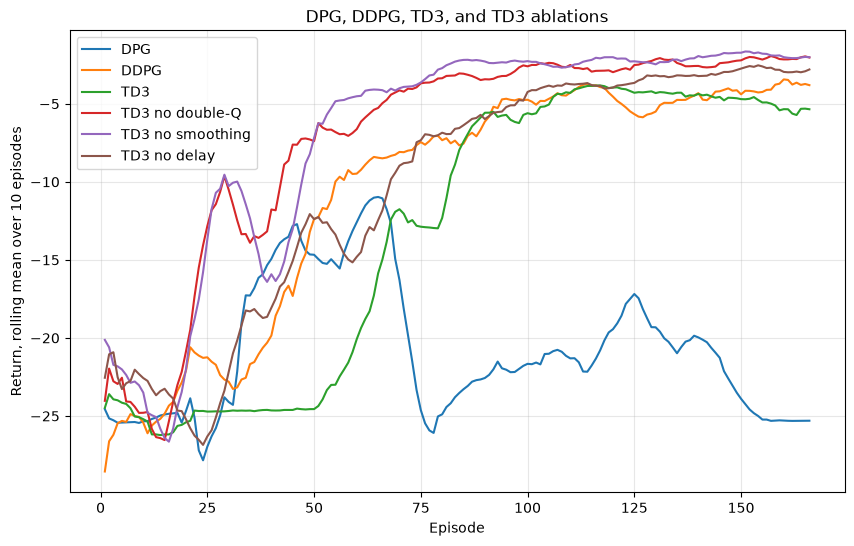


Evaluation summary:
DPG               : {'eval_return': -25.708218501418777, 'eval_return_std': 0.026892468187263624, 'eval_distance': 0.15138822330534457}
DDPG              : {'eval_return': -2.150712610112181, 'eval_return_std': 0.014479604504131249, 'eval_distance': 0.01410895074888443}
TD3               : {'eval_return': -4.708200090350043, 'eval_return_std': 0.09529018243348819, 'eval_distance': 0.03137878481888522}
TD3 no double-Q   : {'eval_return': -1.193733512905969, 'eval_return_std': 0.007954047201658928, 'eval_distance': 0.007783073103055357}
TD3 no smoothing  : {'eval_return': -1.5855755992681018, 'eval_return_std': 0.037810665910014946, 'eval_distance': 0.010382211895659566}
TD3 no delay      : {'eval_return': -2.4524072631788734, 'eval_return_std': 0.037054630773811374, 'eval_distance': 0.01625402139748136}

TD3 ablation analysis:
Full TD3 eval_return: -4.7082
TD3 no double-Q   : eval_return=-1.1937 | drop=-3.5145 | performance improvement
TD3 no smoothing  : eval_retur

In [18]:
import matplotlib.pyplot as plt


def clone_td3_config(base_cfg, **overrides):
    params = {
        "gamma": base_cfg.gamma,
        "actor_lr": base_cfg.actor_lr,
        "critic_lr": base_cfg.critic_lr,
        "tau": base_cfg.tau,
        "noise_std": base_cfg.noise_std,
        "hidden": base_cfg.hidden,
        "replay_size": base_cfg.replay_size,
        "batch_size": base_cfg.batch_size,
        "update_after": base_cfg.update_after,
        "update_every": base_cfg.update_every,
        "use_target_networks": base_cfg.use_target_networks,
        "use_ou_noise": base_cfg.use_ou_noise,
        "policy_delay": base_cfg.policy_delay,
        "target_noise_std": base_cfg.target_noise_std,
        "target_noise_clip": base_cfg.target_noise_clip,
        "use_double_q": base_cfg.use_double_q,
        "use_target_policy_smoothing": base_cfg.use_target_policy_smoothing,
        "use_delayed_policy_updates": base_cfg.use_delayed_policy_updates,
    }
    params.update(overrides)
    return TD3Config(**params)


ablation_configs = {
    "TD3 no double-Q": clone_td3_config(
        td3_cfg,
        use_double_q=False,
    ),
    "TD3 no smoothing": clone_td3_config(
        td3_cfg,
        use_target_policy_smoothing=False,
        target_noise_std=0.0,
        target_noise_clip=0.0,
    ),
    "TD3 no delay": clone_td3_config(
        td3_cfg,
        use_delayed_policy_updates=False,
        policy_delay=1,
    ),
}

ablation_agents = {}
ablation_histories = {}
ablation_eval_stats = {}

for i, (name, ablation_cfg) in enumerate(ablation_configs.items()):
    print(f"\nTraining {name}")
    seed = 100 + 10 * i
    np.random.seed(seed)
    torch.manual_seed(seed)

    ablation_agent = TD3Agent(env, ablation_cfg)
    ablation_history = train_agent(
        env,
        ablation_agent,
        steps=TRAIN_STEPS,
        seed=seed,
        log_every=1000,
    )
    ablation_stats = evaluate(
        env,
        ablation_agent,
        episodes=5,
        seed=8000 + i * 100,
    )

    ablation_agents[name] = ablation_agent
    ablation_histories[name] = ablation_history
    ablation_eval_stats[name] = ablation_stats

    print(name, ablation_stats)

all_histories = {
    "DPG": dpg_history,
    "DDPG": ddpg_history,
    "TD3": td3_history,
    **ablation_histories,
}

all_eval_stats = {
    "DPG": dpg_eval_stats,
    "DDPG": ddpg_eval_stats,
    "TD3": td3_eval_stats,
    **ablation_eval_stats,
}


def rolling_mean(values, window=10):
    values = np.asarray(values, dtype=np.float32)

    if len(values) == 0:
        return values

    out = np.empty_like(values, dtype=np.float32)

    for i in range(len(values)):
        start = max(0, i - window + 1)
        out[i] = values[start:i + 1].mean()

    return out


# ------------------------------------------------------------
# Plot learning curves
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for label, history in all_histories.items():
    returns = history["returns"]

    if len(returns) == 0:
        continue

    smoothed_returns = rolling_mean(returns, window=10)
    episodes = np.arange(1, len(smoothed_returns) + 1)

    plt.plot(episodes, smoothed_returns, label=label)

plt.xlabel("Episode")
plt.ylabel("Return, rolling mean over 10 episodes")
plt.title("DPG, DDPG, TD3, and TD3 ablations")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# ------------------------------------------------------------
# Print evaluation summary
# ------------------------------------------------------------

print("\nEvaluation summary:")
for name, stats in all_eval_stats.items():
    print(f"{name:18s}: {stats}")


# ------------------------------------------------------------
# Analyze TD3 ablations correctly
# Higher return is better.
# Since returns are negative, -1 is better than -5.
# ------------------------------------------------------------

full_td3_return = all_eval_stats["TD3"]["eval_return"]

ablation_drops = {
    name: full_td3_return - stats["eval_return"]
    for name, stats in ablation_eval_stats.items()
}

print("\nTD3 ablation analysis:")
print(f"Full TD3 eval_return: {full_td3_return:.4f}")

for name, drop in ablation_drops.items():
    ablation_return = ablation_eval_stats[name]["eval_return"]

    if drop > 0:
        status = "performance drop"
    elif drop < 0:
        status = "performance improvement"
    else:
        status = "no change"

    print(
        f"{name:18s}: "
        f"eval_return={ablation_return:.4f} | "
        f"drop={drop:+.4f} | "
        f"{status}"
    )


positive_drops = {
    name: drop
    for name, drop in ablation_drops.items()
    if drop > 0
}

if len(positive_drops) == 0:
    print(
        "\nNo TD3 ablation produced a performance drop relative to full TD3 in this run. "
        "In this short single-seed experiment, the ablated TD3 variants performed better than "
        "or equal to full TD3. Therefore, we should not conclude that any removed TD3 component "
        "mattered most based only on this run."
    )
else:
    largest_drop_name = max(positive_drops, key=positive_drops.get)
    largest_drop_value = positive_drops[largest_drop_name]

    print(
        "\nLargest TD3 ablation drop relative to full TD3: "
        f"{largest_drop_name} with drop={largest_drop_value:.4f}. "
        "This identifies the removed component that hurt performance most in this run."
    )


# ------------------------------------------------------------
# Find best method overall
# ------------------------------------------------------------

best_method = max(
    all_eval_stats,
    key=lambda name: all_eval_stats[name]["eval_return"],
)

print(
    "\nBest method in this run: "
    f"{best_method} "
    f"with eval_return={all_eval_stats[best_method]['eval_return']:.4f} "
    f"and eval_distance={all_eval_stats[best_method]['eval_distance']:.4f}."
)
